# Process Trees from DMBD dataset

From LLNL page:

```
In addition to the ACME datasets, we also have the Dynamic Malware Behavior Dataset. This dataset is derived from 65,416 software samples with comprehensive execution logs. It can be used for training and evaluating machine learning models to distinguish between malicious and benign software based on their runtime behavior, with baseline accuracy of 95% that researchers are challenged to surpass.
```

* Data files can be found here: ```https://gdo168.llnl.gov/data/dmbd/```
* There are 8 large files with the data; pre-processing and extracting the required information is done in notebook ```clean_trees``` and saved in ```Data/all_trees.feather```
* only trees of size 3+ are retained


In [1]:
import pandas as pd
import numpy as np
import igraph as ig
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc

## our matching algorithm
import sys
import os
sys.path.insert(0,os.path.abspath('../Matching'))
import igraph_io as igio
import fast_match as fm  ## fast version

from dmbd_util import *


# Build the process trees

Build edges ```parent --> guid```

Process names are all hashes

We'll use either the ```malicious``` or ```test``` label for our exepriments.


In [2]:
# Read the entire feather file (prepared from other notebook)
process_summary = pd.read_feather('Data/all_trees.feather')

# Display the first few rows
print(process_summary.head())


        guid     parent process_name               timestamp  image_loads  \
0  G10154306              P76293.exe                     NaT            0   
1   G4029480  G10154306   P71830.exe 2024-08-24 16:31:37.055            0   
2  G18232545   G4029480   P85969.exe 2024-08-24 16:31:37.241            0   
3   G3413406  G18232545    P4164.exe 2024-08-24 16:31:37.338            0   
4  G20155766   G3413406   P51509.exe 2024-08-24 16:31:37.399            0   

   file_ops  network_connects experiment  malicious  test  
0         0                 0         E0       True  True  
1         0                 0         E0       True  True  
2         0                 0         E0       True  True  
3         0                 0         E0       True  True  
4         0                 0         E0       True  True  


In [3]:
%%time
#process_summary = process_summary[process_summary.parent != '']
Trees = extract_process_trees(process=process_summary, uid='guid', parent_uid='parent',
                              min_tree_size=3, max_tree_size=1000000,
                              extra={'malicious':'malicious','test':'test','process_name':'process'})


CPU times: user 3.56 s, sys: 210 ms, total: 3.77 s
Wall time: 3.78 s


In [4]:
## we'll use those throughout
dct_label = dict(zip(process_summary.guid, process_summary.malicious))
dct_test = dict(zip(process_summary.guid, process_summary.test))
dct_processname = dict(zip(process_summary.guid, process_summary.process_name))


In [5]:
## for plotting - malicious nodes in red
Trees.graph.vs['label_color'] = 'black'
Trees.graph.vs['color'] = 'black'
for v in Trees.graph.vs:
    if dct_label.get(v['uid'],0)>0:
        v['label_color']='red'
        v['color']='red'

# EDA

In [6]:
len(Trees)

34097

largest tree: [(9827, 4529)]


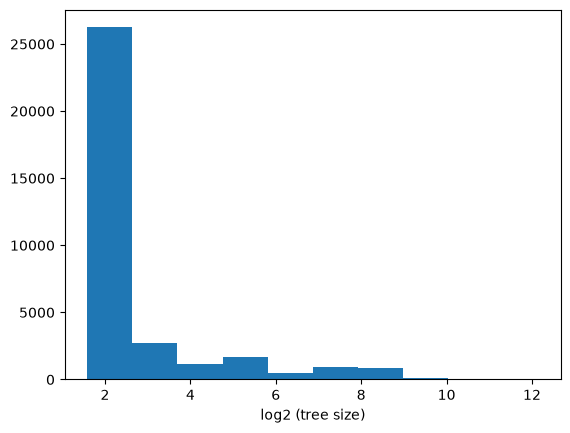

In [7]:
plt.hist([np.log2(x) for x in Trees.sizes()])
plt.xlabel('log2 (tree size)')
print('largest tree:', Counter(Trees.graph.vs['tree']).most_common(1))


### label each tree 

* Each tree has either all nodes malicious, or not
* Each tree has either all or no test nodes


In [8]:
## trees with malicious label(s)
_df = pd.DataFrame( np.array([Trees.graph.vs['tree'] , Trees.graph.vs['malicious']]).T,columns=['tree','malicious'])
print('mean number of malicious nodes per tree:',Counter(_df.groupby(by='tree')['malicious'].mean().to_list()))
tree_is_malicious = np.array(_df.groupby(by='tree')['malicious'].sum().to_list())>0

## trees with test nodes
_df = pd.DataFrame( np.array([Trees.graph.vs['tree'] , Trees.graph.vs['test']]).T,columns=['tree','test'])
print('mean number of test nodes per tree:',Counter(_df.groupby(by='tree')['test'].mean().to_list()))
tree_is_test = np.array(_df.groupby(by='tree')['test'].sum().to_list())>0

mean number of malicious nodes per tree: Counter({1.0: 24602, 0.0: 9495})
mean number of test nodes per tree: Counter({0.0: 18784, 1.0: 15313})


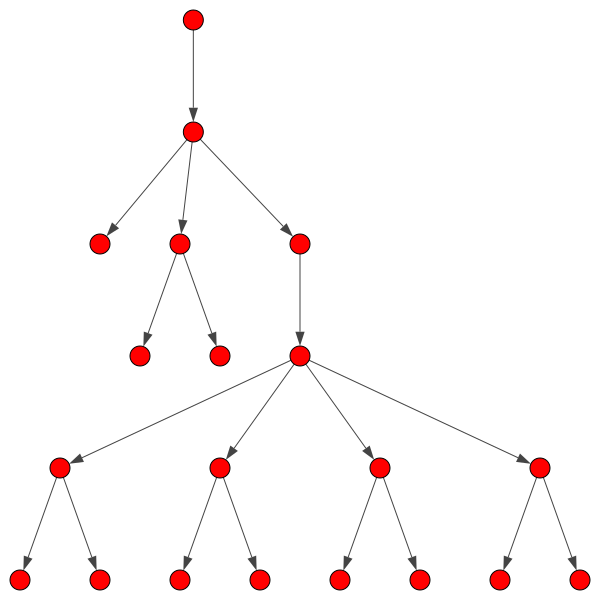

In [9]:
## example - malicious tree
idx = np.where( (np.array(Trees.sizes())==20) & (tree_is_malicious) )[0][0]
sg = Trees.subgraph(idx)
ly = sg.layout_reingold_tilford()
ig.plot(sg, layout=ly, vertex_label_size=0)


### Tree depth distribution

It turns out tree depth is a strong indication of malicious/non-malicious


most common depth: [(np.int64(2), 24272), (np.int64(3), 3471), (np.int64(4), 1626), (np.int64(9), 638), (np.int64(5), 563)]
deepest: 1317
deepest non-malicious: 8


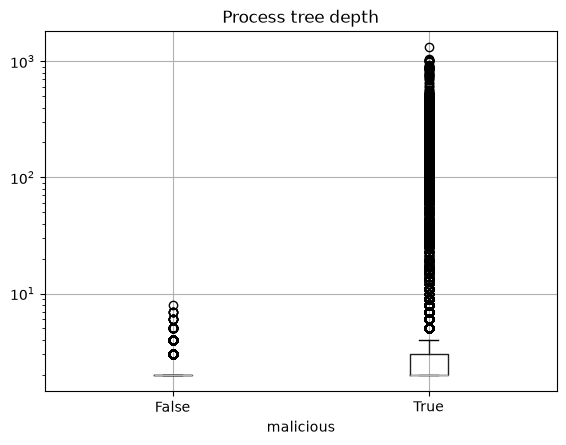

In [10]:
# Tree depth distribution
Subgraphs = Trees.subgraphs()
depths = np.empty(len(Trees), dtype="int64")
L = []
for tree_id in range(len(Trees)):
    tree = Subgraphs[tree_id]
    root = np.argmin(np.array(tree.degree(mode='in')))
    depth = max(tree.distances(root)[0]) # Trees are padded with extra start root
    depths[tree_id] = depth
    L.append([tree_id, tree.vcount(), sum(tree.vs['malicious']), sum(tree.vs['test']), depth ])
Trees.graph.vs['tree_depth'] = [depths[i] for i in Trees.graph.vs['tree']]
depth_df = pd.DataFrame(L, columns=['tree','size','malicious','test','depth'])
depth_df['malicious'] = (depth_df['malicious']>0)
depth_df['test'] = (depth_df['test']>0)

depth_df.boxplot(column="depth", by="malicious", showfliers=True)
plt.yscale('log')
plt.title("Process tree depth")
plt.suptitle("") 

print('most common depth:',Counter(depths).most_common(5))
print('deepest:',max(depths))
print('deepest non-malicious:',max(depth_df[depth_df.malicious==False]['depth']))
plt.show()


# Experiment #1 - Top match between two sets of trees


### (1a) Malicious vs non-malicious trees

In [11]:
## select deep trees
red_trees = list(depth_df[ (depth_df.depth>=5) & (depth_df.malicious) ]['tree'])
black_trees = list(depth_df[ (depth_df.depth>=5) & (depth_df.malicious == False) ]['tree'])

Graphs = []
TreeData = []
nrt = 0
nbt = 0

## pre-processing
for i in red_trees:
    sg = Subgraphs[i]
    if sg.vcount() == (sg.ecount()+1): ## debug
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        nrt += 1

for i in black_trees:
    sg = Subgraphs[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        nbt += 1
        
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## compare all paits
Sim = np.zeros(shape=(nrt, nbt))
Paths = []
for i in range(nrt):
    for j in range(nbt):
        _, score = fast.predict_encoded(enc[i], enc[j+nrt])
        Sim[i,j] = score
print('max score:', np.max(Sim))
print('number of pairs with max score:', sum(Sim.flatten() == np.max(Sim)))

## pick a top similarity pair
(bad, nonbad) = np.unravel_index(np.argmax(Sim), Sim.shape)
sg1 = Graphs[bad]
sg2 = Graphs[nonbad+nrt]


max score: 6.0
number of pairs with max score: 801


Score: 6.0


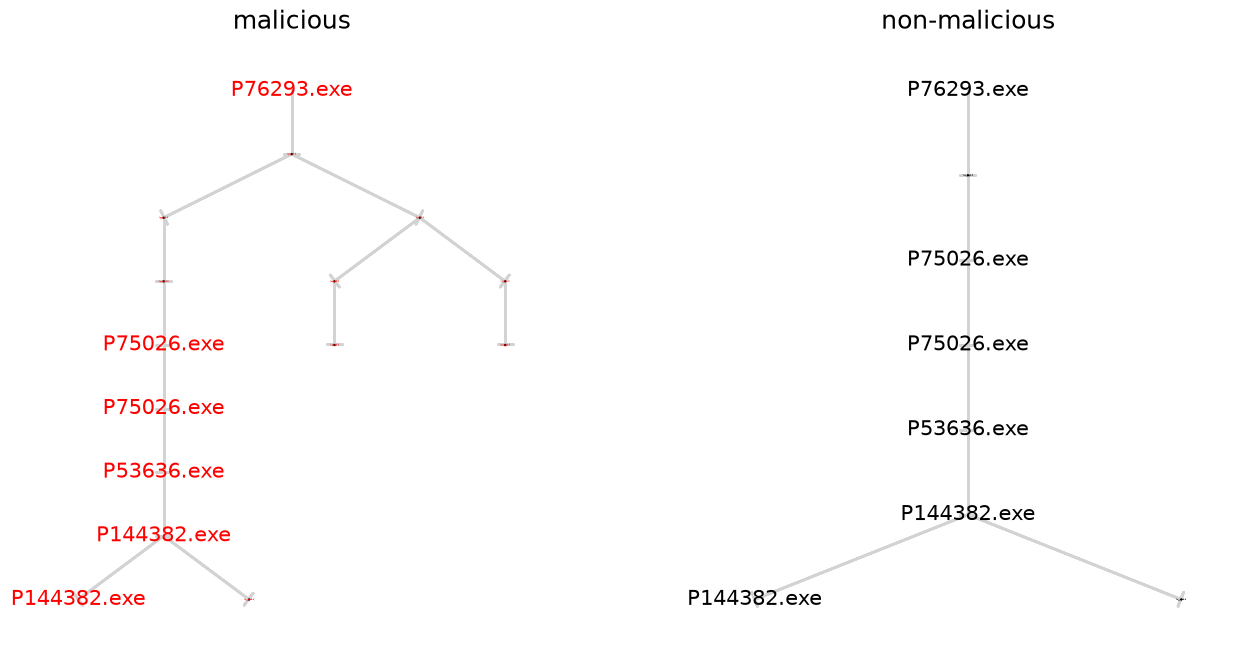

In [12]:
## plot best result
_sg1 = igio.igraph_to_treedata(sg1, phi_name='process')
_sg2 = igio.igraph_to_treedata(sg2, phi_name='process')
match = nwt.align_trees_algorithm1(_sg1, _sg2)
plot_path((sg1,sg2), match.path_internal, margin=(0.1,0.1), titles=['malicious','non-malicious'], size=(16,8))
print('Score:',match.score)


### (1b) test vs non-test trees


In [13]:
## select deep trees
red_trees = list(depth_df[ (depth_df.depth>=100) & (depth_df.test) ]['tree'])
black_trees = list(depth_df[ (depth_df.depth>=100) & (depth_df.test == False) ]['tree'])

Graphs = []
TreeData = []
nrt = 0
nbt = 0

## pre-processing
for i in red_trees:
    sg = Subgraphs[i]
    if sg.vcount() == (sg.ecount()+1): ## debug
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        nrt += 1

for i in black_trees:
    sg = Subgraphs[i]
    if sg.vcount() == (sg.ecount()+1):
        Graphs.append(sg)
        TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
        nbt += 1
        
## encode all trees
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]

## compare all paits
Sim = np.zeros(shape=(nrt, nbt))
Paths = []
for i in range(nrt):
    for j in range(nbt):
        _, score = fast.predict_encoded(enc[i], enc[j+nrt])
        Sim[i,j] = score
print('max score:', np.max(Sim))
print('number of pairs with max score:', sum(Sim.flatten() == np.max(Sim)))

## pick a top similarity pair
(bad, nonbad) = np.unravel_index(np.argmax(Sim), Sim.shape)
sg1 = Graphs[bad]
sg2 = Graphs[nonbad+nrt]
print('test tree has',sg1.vcount(),'nodes and',sg1.ecount(),'edges')
print('non-test tree has',sg2.vcount(),'nodes and',sg2.ecount(),'edges')


max score: 351.0
number of pairs with max score: 1
test tree has 999 nodes and 998 edges
non-test tree has 1318 nodes and 1317 edges


# Experiment #2 - performance test
 

In [14]:
import time
L = []

for N in [int(np.round(np.sqrt(2**i))) for i in np.arange(11,21)]: ## 
    
    Graphs = []
    TreeData = []
    n_train = 0
    n_test = 0

    for i in red_trees[:N]:
        sg = Subgraphs[i]
        if sg.vcount() == (sg.ecount()+1):
            Graphs.append(sg)
            TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
            n_train += 1

    for i in black_trees[:N]:
        sg = Subgraphs[i]
        if sg.vcount() == (sg.ecount()+1):
            Graphs.append(sg)
            TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
            n_test += 1

    ## encode all trees
    fast = fm.FastTreePathMatcher()
    fast.fit_encoder(TreeData)
    enc = [fast.encode_tree(t) for t in TreeData]

    before = time.time()    
    for i in range(n_train):
        for j in range(n_test):
            _, score = fast.predict_encoded(enc[i], enc[j+n_train])
    t_fast = time.time()-before

    if len(L)==0:
        before = time.time()    
        for i in range(n_train):
            for j in range(n_test):
                match = nwt.align_trees_algorithm1(TreeData[i],TreeData[j+n_train])  
        t_slow = time.time()-before
        print('ratio slow vs fast:',t_slow/t_fast)

    L.append([n_train*n_test, t_fast])


ratio slow vs fast: 225.95252549358378


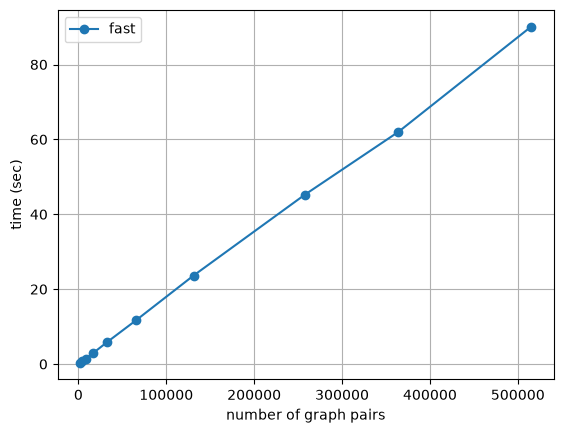

In [15]:
_df = pd.DataFrame(L, columns=['tests','fast'])
plt.plot(_df.tests,_df.fast,'o-',label='fast')
plt.grid()
plt.legend()
plt.xlabel('number of graph pairs')
plt.ylabel('time (sec)');


# Experiment #3 - Template-based classification

* We use the ```test``` flag to divide into train/test sets
* We use the ```malicious``` flag as label


### (3a) randomly chosen templates

chosen from the training set

In [16]:
## pre-processing
Graphs = []
TreeData = []
for i in range(len(Subgraphs)):
    sg = Subgraphs[i]
    Graphs.append(sg)
    TreeData.append(igio.igraph_to_treedata(sg, phi_name='process'))
## encoding
fast = fm.FastTreePathMatcher()
fast.fit_encoder(TreeData)
enc = [fast.encode_tree(t) for t in TreeData]


In [17]:
min_depth = 3
n_template = 128

## train/test split
train_trees = np.sort(depth_df[ (depth_df.depth>=min_depth) & (depth_df.test == 0) ]['tree']).tolist()
test_trees = list(depth_df[ (depth_df.depth>=min_depth) & (depth_df.test > 0) ]['tree'])

## pick some train for templates
np.random.seed(123)
template_trees = np.random.choice(train_trees, n_template, replace=False)
train_trees = list(set(train_trees).difference(set(template_trees)))

n_train = len(train_trees)
n_test = len(test_trees)


In [18]:
## compare train/test trees to the template trees
Sim = np.zeros(shape=(n_template, n_train+n_test))
for i in range(n_template):
    for j in range(n_train):
        _, score = fast.predict_encoded(enc[template_trees[i]], enc[train_trees[j]])
        Sim[i,j] = score
    for j in range(n_test):
        _, score = fast.predict_encoded(enc[template_trees[i]], enc[test_trees[j]])
        Sim[i,j+n_train] = score
Sim.shape


(128, 9697)

In [19]:
## train/test RF model
X = Sim.T.tolist()
X_train = X[:n_train]
X_test = X[n_train:(n_train+n_test)]
tree_label = dict(zip(depth_df.tree, depth_df.malicious))
y_train = [tree_label[i] for i in train_trees]
y_test = [tree_label[i] for i in test_trees]

# ## optional -- add depth as a feature
# d = list(_df.depth)
# _ = np.array([d[i] for i in train_trees if i not in drop])
# X_train = np.column_stack( (np.array(X_train) , _) )
# _ = np.array([d[i] for i in test_trees if i not in drop])
# X_test = np.column_stack( (np.array(X_test) , _) )

rf = RandomForestClassifier(n_jobs=4, random_state=123)
rf.fit(X_train, y_train)
y_pred_proba = rf.predict_proba(X_test)[:,1]
fpr1, tpr1, thresholds1 = roc_curve(y_test, y_pred_proba)
print('AUC:',auc(fpr1, tpr1))


AUC: 0.9228845723505995


### (3b) chosen templates from training set

- pick random batch for template, score all training
- pick new batch, most different from current set, add to set
- rince and repeat


In [20]:
train_trees = list(depth_df[ (depth_df.depth>=min_depth) & (depth_df.test == 0) ]['tree'])

## first batch
batch_size = 16
np.random.seed(123)
template_trees = list(np.random.choice(train_trees, batch_size, replace=False))
train_trees = list(set(train_trees).difference(set(template_trees)))


In [21]:
### ...
for _rep in range(7):
    ## compare all and add new batch
    Sim = np.zeros(shape=(len(template_trees), len(train_trees))) 
    for i in range(len(template_trees)):
        for j in range(len(train_trees)):
            _, score = fast.predict_encoded(enc[template_trees[i]], enc[train_trees[j]])
            Sim[i,j] = score
    ## new batch
    new_batch = [train_trees[i] for i in np.argsort(Sim.max(axis=0))[:batch_size]] ## could try other things
    template_trees.extend(new_batch)
    train_trees = list(set(train_trees).difference(set(template_trees)))


In [22]:
## compare train/test trees to the template trees
Sim = np.zeros(shape=(n_template, n_train+n_test))
for i in range(n_template):
    for j in range(n_train):
        _, score = fast.predict_encoded(enc[template_trees[i]], enc[train_trees[j]])
        Sim[i,j] = score
    for j in range(n_test):
        _, score = fast.predict_encoded(enc[template_trees[i]], enc[test_trees[j]])
        Sim[i,j+n_train] = score
Sim.shape


(128, 9697)

In [23]:
## train/test RF model
X = Sim.T.tolist()
X_train = X[:n_train]
X_test = X[n_train:(n_train+n_test)]
tree_label = dict(zip(depth_df.tree, depth_df.malicious))
y_train = [tree_label[i] for i in train_trees]
y_test = [tree_label[i] for i in test_trees]

rf = RandomForestClassifier(n_jobs=4, random_state=123)
rf.fit(X_train, y_train)
y_pred_proba = rf.predict_proba(X_test)[:,1]
fpr2, tpr2, thresholds2 = roc_curve(y_test, y_pred_proba)
print('AUC:',auc(fpr2, tpr2))


AUC: 0.9496354792358608


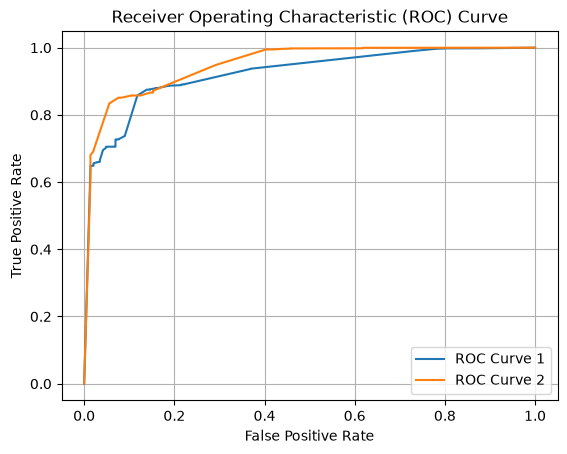

In [24]:
plt.plot(fpr1, tpr1, label='ROC Curve 1')
plt.plot(fpr2, tpr2, label='ROC Curve 2')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid()
plt.show()
